In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Localizar a raiz do projeto
RAIZ_PROJETO = Path.cwd().parent

CAMINHO_DADOS = (
    RAIZ_PROJETO
    / "data"
    / "processed"
    / "focos_mensais.csv"
)

df = pd.read_csv(
    CAMINHO_DADOS,
    parse_dates=["mes"]
)

print("Dimensões:", df.shape)

display(df.head())

Dimensões: (26016, 4)


,estado,municipio,mes,qtd_focos
0,ACRE,ACRELÂNDIA,2022-01-01,0
1,ACRE,ACRELÂNDIA,2022-02-01,0
2,ACRE,ACRELÂNDIA,2022-03-01,0
3,ACRE,ACRELÂNDIA,2022-04-01,0
4,ACRE,ACRELÂNDIA,2022-05-01,1


## Evolução temporal das detecções

Este gráfico apresenta a quantidade mensal de focos de calor
detectados pelo satélite de referência do INPE no bioma Amazônia
brasileiro, entre janeiro de 2022 e dezembro de 2025.

As contagens representam detecções registradas, não necessariamente
incêndios individuais ou área queimada.

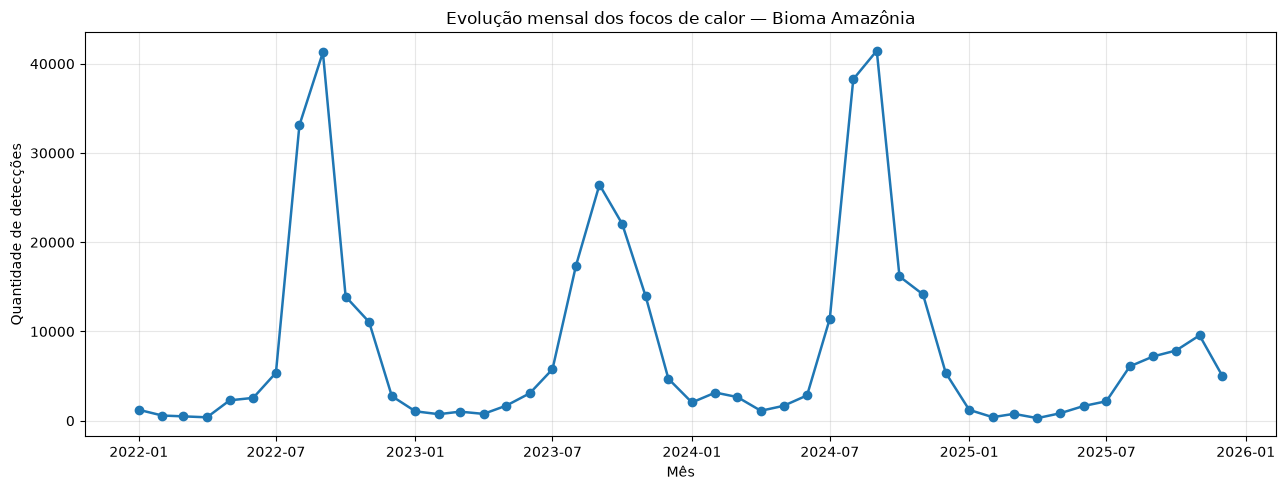

In [3]:
# Agrupar as detecções por mês
focos_por_mes = (
    df.groupby("mes")["qtd_focos"]
    .sum()
    .sort_index()
)

# Criar o gráfico
plt.figure(figsize=(13, 5))

plt.plot(
    focos_por_mes.index,
    focos_por_mes.values,
    marker="o",
    linewidth=1.8
)

plt.title("Evolução mensal dos focos de calor — Bioma Amazônia")
plt.xlabel("Mês")
plt.ylabel("Quantidade de detecções")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Distribuição mensal das detecções por município

Analisamos a distribuição das contagens mensais para entender a frequência
de meses sem detecções e identificar possíveis critérios para classificar
períodos de alta concentração.

Para evitar vazamento de informações, os limites de classificação serão
definidos usando somente os dados de treinamento (2022–2024).

In [4]:
# Separar os dados de treinamento (2022 a 2024)
treino = df[df["mes"].dt.year <= 2024].copy()

# Calcular estatísticas descritivas
print("Estatísticas mensais por município — 2022 a 2024:")
print(
    treino["qtd_focos"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Verificar a proporção de meses sem detecções
proporcao_zeros = (treino["qtd_focos"] == 0).mean()

print(
    f"\nMeses sem detecções: {proporcao_zeros:.1%}"
)

# Examinar a distribuição apenas dos meses com detecções
meses_positivos = treino.loc[
    treino["qtd_focos"] > 0,
    "qtd_focos"
]

print("\nEstatísticas dos meses com pelo menos uma detecção:")
print(
    meses_positivos.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Estatísticas mensais por município — 2022 a 2024:
count    19512.000000
mean        18.143604
std         98.645282
min          0.000000
50%          1.000000
75%          7.000000
90%         30.000000
95%         68.000000
99%        293.000000
max       3967.000000
Name: qtd_focos, dtype: float64

Meses sem detecções: 45.8%

Estatísticas dos meses com pelo menos uma detecção:
count    10569.000000
mean        33.495884
std        132.103048
min          1.000000
50%          6.000000
75%         21.000000
90%         61.000000
95%        131.000000
99%        477.320000
max       3967.000000
Name: qtd_focos, dtype: float64


In [5]:
# Limite definido a partir do período de treinamento
LIMITE_ALTA_CONCENTRACAO = 30

# Classificar os meses do treinamento
treino["alta_concentracao"] = (
    treino["qtd_focos"] >= LIMITE_ALTA_CONCENTRACAO
).astype(int)

print("Distribuição das classes — 2022 a 2024:")
print(treino["alta_concentracao"].value_counts())

print("\nDistribuição percentual:")
print(
    treino["alta_concentracao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribuição por ano:")
print(
    pd.crosstab(
        treino["mes"].dt.year,
        treino["alta_concentracao"],
        normalize="index"
    ).mul(100).round(2)
)

Distribuição das classes — 2022 a 2024:
alta_concentracao
0    17523
1     1989
Name: count, dtype: int64

Distribuição percentual:
alta_concentracao
0    89.81
1    10.19
Name: proportion, dtype: float64

Distribuição por ano:
alta_concentracao      0      1
mes                            
2022               90.85   9.15
2023               89.54  10.46
2024               89.02  10.98
